In [1]:

import pandas as pd
import re
import unicodedata

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Đọc dữ liệu gốc
data_path = Path("../data/raw/shopee_reviews_dataset.jsonl")

df = pd.read_json(data_path, lines=True)

print("Dataset shape:", df.shape)
print("Label distribution:")
print(df["label"].value_counts())


Dataset shape: (9599, 4)
Label distribution:
label
negative    5965
positive    3634
Name: count, dtype: int64


In [2]:

NEGATION_MAP = {
    "ko": "không",
    "k": "không",
    "khum": "không",
}

NEGATION_PATTERN = re.compile(
    r"\b(?:ko|k|khum)\b",
    flags=re.IGNORECASE
)

URL_PATTERN = re.compile(
    r"https?://\S+|www\.\S+",
    flags=re.IGNORECASE
)

WHITESPACE_PATTERN = re.compile(r"\s+")

def preprocess_text(text):
    if pd.isna(text):
        return ""

    text = str(text)
    text = unicodedata.normalize("NFC", text)
    text = text.lower()
    text = URL_PATTERN.sub(" ", text)

    text = NEGATION_PATTERN.sub(
        lambda match: NEGATION_MAP[match.group(0)],
        text
    )

    text = WHITESPACE_PATTERN.sub(" ", text).strip()

    return text


#### Kiểm tra trùng lặp và nhãn mâu thuẫn

In [12]:

# Tạo bản sao, không chỉnh sửa dataset gốc
df_model = df.copy()

# Chuẩn hóa review để kiểm tra trùng
df_model["review_clean"] = (
    df_model["review"].apply(preprocess_text)
)

# Lấy tất cả bản ghi có nội dung trùng
duplicates = df_model[
    df_model.duplicated(
        subset=["review_clean"],
        keep=False
    )
].sort_values("review_clean")

print("Số bản ghi thuộc nhóm trùng:", len(duplicates))
print(
    "Số bản ghi trùng dư:",
    df_model.duplicated(subset=["review_clean"]).sum()
)

# Kiểm tra cùng nội dung nhưng khác nhãn
label_counts = (
    df_model.groupby("review_clean")["label"]
    .nunique()
)

conflicting_texts = label_counts[
    label_counts > 1
].index

conflicts = df_model[
    df_model["review_clean"].isin(conflicting_texts)
]

print("\nSố nội dung có nhãn mâu thuẫn:", len(conflicting_texts))

if len(conflicts) > 0:
    print("\nCác review trùng nhưng khác nhãn:")
    display(
        conflicts[
            ["id", "review", "review_clean", "label"]
        ]
    )
else:
    print("Không phát hiện nội dung trùng có nhãn mâu thuẫn.")


Số bản ghi thuộc nhóm trùng: 8
Số bản ghi trùng dư: 4

Số nội dung có nhãn mâu thuẫn: 0
Không phát hiện nội dung trùng có nhãn mâu thuẫn.


### Tạo dataset thực nghiệm không trùng

In [13]:
if len(conflicting_texts) > 0:
    raise ValueError(
        "Có review trùng nhưng khác nhãn. "
        "Cần kiểm tra và xử lý trước khi tiếp tục."
    )

original_size = len(df_model)

# Loại bản ghi trùng sau chuẩn hóa
df_model = (
    df_model
    .drop_duplicates(
        subset=["review_clean"],
        keep="first"
    )
    .reset_index(drop=True)
)

removed = original_size - len(df_model)

print("Dataset ban đầu:", original_size)
print("Số bản ghi trùng đã loại:", removed)
print("Dataset sau xử lý:", len(df_model))

print("\nPhân bố nhãn sau xử lý:")
print(df_model["label"].value_counts())


Dataset ban đầu: 9599
Số bản ghi trùng đã loại: 4
Dataset sau xử lý: 9595

Phân bố nhãn sau xử lý:
label
negative    5961
positive    3634
Name: count, dtype: int64


### Chia 70% Train, 15% Validation, 15% Test

In [14]:
# Dùng dataset thực nghiệm đã loại trùng
X = df_model["review"].astype(str)
y = df_model["label"]

# 85% Train + Validation, 15% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Chia tiếp để đạt tỷ lệ 70/15/15
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nTỷ lệ phân bố nhãn:")
display(
    pd.DataFrame({
        "Train": y_train.value_counts(normalize=True),
        "Validation": y_val.value_counts(normalize=True),
        "Test": y_test.value_counts(normalize=True)
    })
)


Train: 6715
Validation: 1440
Test: 1440

Tỷ lệ phân bố nhãn:


,Train,Validation,Test
label,,,
negative,0.621147,0.621528,0.621528
positive,0.378853,0.378472,0.378472


### Tạo Pipeline TF-IDF + Naive Bayes

In [15]:

baseline_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            preprocessor=preprocess_text,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        MultinomialNB()
    )
])

baseline_pipeline.fit(X_train, y_train)

print("Baseline model trained successfully!")


Baseline model trained successfully!


### Đánh giá trên Validation

Validation Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

    negative     0.9376    0.9564    0.9469       895
    positive     0.9260    0.8954    0.9104       545

    accuracy                         0.9333      1440
   macro avg     0.9318    0.9259    0.9287      1440
weighted avg     0.9332    0.9333    0.9331      1440



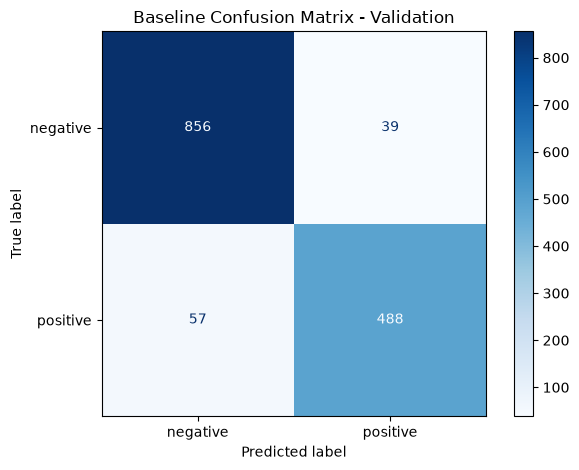

In [16]:

y_val_pred = baseline_pipeline.predict(X_val)

print("Validation Accuracy:",
      round(accuracy_score(y_val, y_val_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=["negative", "positive"],
        digits=4
    )
)

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=["negative", "positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["negative", "positive"]
)

disp.plot(cmap="Blues")
plt.title("Baseline Confusion Matrix - Validation")
plt.tight_layout()
plt.show()


#### Thử dự đoán review mới

In [17]:

sample_reviews = [
    "Sản phẩm rất tốt, giao hàng nhanh, đóng gói cẩn thận",
    "Hàng bị lỗi, chất lượng quá tệ, rất thất vọng",
    "Shop giao không đúng mẫu, tôi không hài lòng",
    "Sản phẩm đẹp, giá hợp lý, sẽ mua lại"
]

predictions = baseline_pipeline.predict(sample_reviews)

for review, label in zip(sample_reviews, predictions):
    print("Review:", review)
    print("Prediction:", label)
    print("-" * 60)


Review: Sản phẩm rất tốt, giao hàng nhanh, đóng gói cẩn thận
Prediction: positive
------------------------------------------------------------
Review: Hàng bị lỗi, chất lượng quá tệ, rất thất vọng
Prediction: negative
------------------------------------------------------------
Review: Shop giao không đúng mẫu, tôi không hài lòng
Prediction: negative
------------------------------------------------------------
Review: Sản phẩm đẹp, giá hợp lý, sẽ mua lại
Prediction: positive
------------------------------------------------------------


### Thống kê và hiển thị các review dự đoán sai

In [18]:

# Tạo DataFrame phân tích dự đoán
val_results = pd.DataFrame({
    "review": X_val.to_numpy(),
    "true_label": y_val.to_numpy(),
    "predicted_label": y_val_pred
})

# Lọc các trường hợp dự đoán sai
errors = val_results[
    val_results["true_label"] != val_results["predicted_label"]
].copy()

print("Tổng số review Validation:", len(val_results))
print("Số review dự đoán sai:", len(errors))
print(f"Tỷ lệ lỗi: {len(errors) / len(val_results) * 100:.2f}%")

print("\nPhân loại lỗi:")
display(
    pd.crosstab(
        errors["true_label"],
        errors["predicted_label"]
    )
)

# Hiển thị 15 review dự đoán sai
pd.set_option("display.max_colwidth", None)

display(
    errors.sample(
        n=min(15, len(errors)),
        random_state=42
    )
)


Tổng số review Validation: 1440
Số review dự đoán sai: 96
Tỷ lệ lỗi: 6.67%

Phân loại lỗi:


predicted_label,negative,positive
true_label,,
negative,0,39
positive,57,0


,review,true_label,predicted_label
1145,Size quá to so với mô tả gợi ý chiều cao và cân nặng để người mua chonh size,negative,positive
1081,Mẹo:k Lợi ích:k Làm đẹp:k K có hiệu quả lắm không như giới thiệu nha Ok sản phẩm dễ dùng. mua người mua ủng cho shop nhé . Ah akd shdb njj,negative,positive
1052,"Làm đẹp:ok Bao bì:ok Hương thơm:ok Thề mua lại nhiều lần lắm rồi, đây là săn cho đứa em … Nói chung cái này dùng kẹp ẩm thì có khi 1-2 hôm sau mình không dùng lại thì cũng không bị khô da đâu ý, da mình da dầu nhẹ Ê mà cái phục hồi siêu siêu tốt Tối đó mình nặn mụn da đỏ ửng các thứ luôn, bôi kẹp ẩm em này ( toner - Serum - Toner ) cái sáng hôm sau không đỏ gì luôn 😌😌 Đợt này đang dùng serum Kẽm Ekseption rồi nên là chưa có mua em này dùng, vì sợ hút ẩm x2 🥲",positive,negative
1417,Độ mỏng:mỏng Hương thơm:mùi thơm khó chịu,negative,positive
516,"Sữa pha theo công thức thì ngọt quá, có vị nhợ nhợ hơi mặn. Uống bé tăng cân nhanh. Mỗi tội không ngon thôi",positive,negative
1095,"Hương thơm:chưa biết Nhận đúng sản phẩm quảng cáo, thể loại,dùng sẽ biết có hiểu không.nhưng bao bì đẹp.shop uy tín",positive,negative
984,"Bao bì/Mẫu mã:sữa tươi dutch lady Hương vị:không đường Thùng sữa giao tới trong tình trạng còn nguyên vẹn, không bị móp méo hay bị ỉu. Thùng còn nguyên seal, không bị bong tróc nhờ đóng gói kỹ. Bảng thành phần sữa có nhiều chất, hương vị sữa thơm ngon dù là loại không đường. Phù hợp với trẻ nhỏ",positive,negative
688,Tin tưởng là hàng chính hãng chắc sẽ hiệu quả và lành. Nhưng tuýp foam này khá nhỏ so tưởng tượng,positive,negative
1,"Shop đóng gói cẩn thận. Đã sử dụng gần 1 tháng để đánh giá. Quần chất liệu mặc khá ổn, chun quần có dấu hiệu bai dão dù mới sử dụng.",negative,positive
108,"Đã mua cái thứ 2 , 3 xị mà như hàng dyson :))) , màu tím qá suất sắc đã xài đc năm hi vọng bền bỉ theo năm tháng",positive,negative


### Xem các lỗi mà mô hình tự tin nhất

In [19]:

# Xác suất dự đoán của mô hình
probabilities = baseline_pipeline.predict_proba(X_val)

# Độ tự tin là xác suất lớn nhất trong hai lớp
val_results["confidence"] = probabilities.max(axis=1)

# Lọc các review sai và sắp xếp theo độ tự tin
high_confidence_errors = val_results[
    val_results["true_label"] != val_results["predicted_label"]
].sort_values(
    by="confidence",
    ascending=False
)

print("TOP 20 REVIEW DỰ ĐOÁN SAI VỚI ĐỘ TỰ TIN CAO")

display(
    high_confidence_errors.head(20)
)


TOP 20 REVIEW DỰ ĐOÁN SAI VỚI ĐỘ TỰ TIN CAO


,review,true_label,predicted_label,confidence
227,Phù hợp với loại da:fjfjfh Mùi hương:thơm Công dụng:thơm Chất lượng sản phẩm tuyệt vời Giao hàng nhanh chóng Tư vấn nhiệt tình Sẽ ủng hộ tiếp K có quà như ảnh,negative,positive,0.999370
33,ko thích tuyệt vời giao siêu nhanh nên mua tư vấn nhiệt tình lắm sản phẩm ổn áp,negative,positive,0.994586
538,"Đóng xốp bọc k kĩ nha, chai dán băng dính bọc từ đầu đến cuối chai, bẩn tèm nhem, chả biết như nào nhưng thấy nvay cũng k ổn, shop nên xem lại cách đóng, này là mình săn được nên cũng thôi!",positive,negative,0.989904
913,Hình ảnh chỉ mang tính chất nhận xu thôi ship cũng nhánh chóng. Hi vọng dùng tốt lần sau sẽ mua lại,negative,positive,0.989366
69,"Chất lượng tốt lắm. Shop có thể đừng dùng keo trong dán lên nắp được không. Đã rất cố gắng nhiều lần nhưng mở keo ra lần nào cũng bị dính chai, làm chai bám bụi. Nhìn bẩn và mỗi lần sử dụng đều dính dính vào tay.",positive,negative,0.988616
1324,"Mình mà biết sớm mua trên có quà nhiều vậy , chắc giờ nhà hông có chỗ để luôn quá. Trước toàn mua ngoài cửa hàng nên không có quà gì hết. Từ ngày mua trên trang này quà đã luôn.",positive,negative,0.979531
273,Hộp đến tay hơi móp méo nhẹ mong là khôbg ảnh hưởng đến chất lượng bên trong.,positive,negative,0.958960
382,"Dưỡng tóc:không Giảm gãy rụng:không Cá trê nha, kh nên mua Hình ảnh chỉ mang tính chất nhận xu",negative,positive,0.958075
158,Độ êm:ok Chất liệu:nhựa Màu sắc:nâu shop tư vấn size 35 mà chật quá=)). giao nhanh săn dc với giá khá rẻ,negative,positive,0.950591
263,Shop giao hàng nhanh. Ms đặt hôm 20-21 nhận luôn nè. Chỗ mình đang bị vỡ kho k có ship giao nên đặt hàng mà đc gọi giao hàng là mừng lắm,positive,negative,0.931099


### Kiểm tra trùng lặp giữa các tập

In [20]:


# Chuẩn hóa review bằng hàm preprocess_text đã xây dựng
train_clean = X_train.map(preprocess_text)
val_clean = X_val.map(preprocess_text)
test_clean = X_test.map(preprocess_text)

# Chuyển thành tập hợp để so sánh
train_set = set(train_clean)
val_set = set(val_clean)
test_set = set(test_clean)

# Kiểm tra trùng lặp giữa các tập
train_val_overlap = train_set & val_set
train_test_overlap = train_set & test_set
val_test_overlap = val_set & test_set

print("KIỂM TRA TRÙNG LẶP SAU TIỀN XỬ LÝ")
print("-" * 50)

print("Train - Validation:", len(train_val_overlap))
print("Train - Test:", len(train_test_overlap))
print("Validation - Test:", len(val_test_overlap))

# Kiểm tra trùng trong từng tập
print("\nTRÙNG LẶP NỘI BỘ")

print("Train:", train_clean.duplicated().sum())
print("Validation:", val_clean.duplicated().sum())
print("Test:", test_clean.duplicated().sum())

# Kết luận
if (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
):
    print("\nKhông phát hiện review trùng giữa các tập sau chuẩn hóa.")
else:
    print("\nPhát hiện review trùng giữa các tập.")


KIỂM TRA TRÙNG LẶP SAU TIỀN XỬ LÝ
--------------------------------------------------
Train - Validation: 0
Train - Test: 0
Validation - Test: 0

TRÙNG LẶP NỘI BỘ
Train: 0
Validation: 0
Test: 0

Không phát hiện review trùng giữa các tập sau chuẩn hóa.


#### Hiển thị review trùng

In [21]:


if train_val_overlap:
    print("Ví dụ review trùng giữa Train và Validation:")

    for review in list(sorted(train_val_overlap))[:10]:
        print("-" * 60)
        print(review)

if train_test_overlap:
    print("\nVí dụ review trùng giữa Train và Test:")

    for review in list(sorted(train_test_overlap))[:10]:
        print("-" * 60)
        print(review)

if val_test_overlap:
    print("\nVí dụ review trùng giữa Validation và Test:")

    for review in list(sorted(val_test_overlap))[:10]:
        print("-" * 60)
        print(review)


## Tổng hợp kết quả Baseline sau khi xử lý trùng

In [22]:

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# Dự đoán lại trên Validation mới
y_val_pred = baseline_pipeline.predict(X_val)

# Tính các chỉ số tổng hợp
precision, recall, f1, _ = precision_recall_fscore_support(
    y_val,
    y_val_pred,
    average="macro",
    zero_division=0
)

accuracy = accuracy_score(y_val, y_val_pred)

# Tạo bảng kết quả
baseline_summary = pd.DataFrame([{
    "Model": "TF-IDF + MultinomialNB",
    "Train samples": len(X_train),
    "Validation samples": len(X_val),
    "Test samples": len(X_test),
    "Accuracy": round(accuracy, 4),
    "Macro Precision": round(precision, 4),
    "Macro Recall": round(recall, 4),
    "Macro F1": round(f1, 4)
}])

print("KẾT QUẢ BASELINE SAU KHI LOẠI TRÙNG")
display(baseline_summary)

# Lưu kết quả để sử dụng trong báo cáo
from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

baseline_summary.to_csv(
    results_dir / "baseline_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu results/baseline_metrics.csv")


KẾT QUẢ BASELINE SAU KHI LOẠI TRÙNG


,Model,Train samples,Validation samples,Test samples,Accuracy,Macro Precision,Macro Recall,Macro F1
0,TF-IDF + MultinomialNB,6715,1440,1440,0.9333,0.9318,0.9259,0.9287


Đã lưu results/baseline_metrics.csv


In [23]:

# Chuẩn hóa các tập
train_clean = set(X_train.map(preprocess_text))
val_clean = set(X_val.map(preprocess_text))
test_clean = set(X_test.map(preprocess_text))

# Kiểm tra giao nhau
overlap_train_val = len(train_clean & val_clean)
overlap_train_test = len(train_clean & test_clean)
overlap_val_test = len(val_clean & test_clean)

print("Train - Validation:", overlap_train_val)
print("Train - Test:", overlap_train_test)
print("Validation - Test:", overlap_val_test)

assert overlap_train_val == 0
assert overlap_train_test == 0
assert overlap_val_test == 0

print("\nPASS: Không phát hiện trùng lặp chính xác sau chuẩn hóa giữa các tập.")


Train - Validation: 0
Train - Test: 0
Validation - Test: 0

PASS: Không phát hiện trùng lặp chính xác sau chuẩn hóa giữa các tập.


In [24]:

# Lưu ID và nhãn của từng tập
split_info = pd.concat([
    pd.DataFrame({
        "id": df_model.loc[X_train.index, "id"].to_numpy(),
        "split": "train",
        "label": y_train.to_numpy()
    }),
    pd.DataFrame({
        "id": df_model.loc[X_val.index, "id"].to_numpy(),
        "split": "validation",
        "label": y_val.to_numpy()
    }),
    pd.DataFrame({
        "id": df_model.loc[X_test.index, "id"].to_numpy(),
        "split": "test",
        "label": y_test.to_numpy()
    })
], ignore_index=True)

split_info.to_csv(
    results_dir / "data_splits.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu results/data_splits.csv")
print(split_info["split"].value_counts())


Đã lưu results/data_splits.csv
split
train         6715
validation    1440
test          1440
Name: count, dtype: int64
